# Interpretabilidade de Modelos de Aprendizado de Máquina
## KNN × Naïve Bayes × Árvore de Decisão no problema de risco de crédito (German Credit)

**Disciplina:** Aprendizado de Máquina — Profª. Drª. Daniela Oliveira Ferreira do Amaral
**Aluno:** Leonardo Gemin Pereira (trabalho individual)

Este notebook é o artefato principal do trabalho. Ele cobre todas as etapas pedidas no enunciado:

| Etapa | Seção |
|---|---|
| 1 — Escolha e contextualização do dataset | §1 |
| 2 — Pré-processamento, divisão, treino e avaliação | §2 |
| 3 — Interpretabilidade (Árvore, Naïve Bayes, KNN + SHAP/LIME/Permutação) | §3 |
| 4 — Comparação e análise | §4 |
| Desafio final e conclusões | §5 |

Todas as decisões estão justificadas em células Markdown logo antes ou depois do código correspondente.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42
np.random.seed(SEED)
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# 1. Escolha do conjunto de dados (Etapa 1)

**Dataset:** *Statlog (German Credit Data)* — UCI Machine Learning Repository
(Hofmann, 1994 — <https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data>). O arquivo
`data/german.data` é a versão original simbólica (códigos `A11`, `A12`, ...).

**Problema:** um banco alemão precisa decidir se concede crédito a um solicitante. Cada linha é um
cliente que recebeu crédito, rotulado como **bom pagador** (700) ou **mau pagador** (300). A tarefa é
prever o rótulo a partir de dados cadastrais e financeiros.

**Por que este dataset é adequado ao tema interpretabilidade:**
- Crédito é uma decisão de alto impacto e **regulada**: o cliente tem direito a saber *por que* foi
  recusado (ex.: LGPD art. 20 no Brasil; GDPR na Europa). A pergunta “por que o modelo chegou a essa
  conclusão?” é literalmente uma exigência do domínio.
- Contém atributos sensíveis (idade, sexo/estado civil, trabalhador estrangeiro) — a interpretabilidade
  permite verificar se o modelo se apoia neles.

**Requisitos do enunciado:**

| Requisito | Atendido? |
|---|---|
| ≥ 5 features | 20 features |
| Classificação (alvo categórico) | sim — bom/mau pagador |
| Numéricas **e** categóricas | 7 numéricas + 13 categóricas |
| ≥ 100 instâncias | 1000 |
| Não é Iris/Titanic/Adult/Breast Cancer/Wine | sim |

In [2]:
COLS = ["checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings",
        "employment", "installment_rate", "personal_status_sex", "other_debtors", "residence_since",
        "property", "age", "other_installment_plans", "housing", "existing_credits", "job",
        "num_dependents", "telephone", "foreign_worker", "target"]

raw = pd.read_csv("../data/german.data", header=None, names=COLS)
print(raw.shape)
raw.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


### Decodificação dos códigos simbólicos

Os valores categóricos vêm codificados (`A11`, `A34`, ...). Para que **as explicações sejam legíveis
por um gestor de crédito**, traduzimos cada código para o significado documentado pela UCI. Essa é uma
decisão de interpretabilidade: uma explicação do tipo “`checking_status_A14` reduziu o risco” não serve
a ninguém; “cliente *sem conta corrente* no banco” sim.

In [3]:
CODES = {
    "checking_status": {"A11": "< 0 DM", "A12": "0–200 DM", "A13": ">= 200 DM", "A14": "sem conta corrente"},
    "credit_history": {"A30": "sem créditos / todos pagos", "A31": "todos pagos neste banco",
                       "A32": "créditos atuais em dia", "A33": "atrasos no passado",
                       "A34": "conta crítica / créditos em outros bancos"},
    "purpose": {"A40": "carro novo", "A41": "carro usado", "A42": "móveis", "A43": "rádio/TV",
                "A44": "eletrodomésticos", "A45": "reparos", "A46": "educação", "A47": "férias",
                "A48": "requalificação", "A49": "negócios", "A410": "outros"},
    "savings": {"A61": "< 100 DM", "A62": "100–500 DM", "A63": "500–1000 DM", "A64": ">= 1000 DM",
                "A65": "desconhecida / sem poupança"},
    "employment": {"A71": "desempregado", "A72": "< 1 ano", "A73": "1–4 anos", "A74": "4–7 anos",
                   "A75": ">= 7 anos"},
    "personal_status_sex": {"A91": "masc. divorciado/separado", "A92": "fem. div./sep./casada",
                            "A93": "masc. solteiro", "A94": "masc. casado/viúvo", "A95": "fem. solteira"},
    "other_debtors": {"A101": "nenhum", "A102": "co-requerente", "A103": "fiador"},
    "property": {"A121": "imóvel", "A122": "seguro de vida / poupança", "A123": "carro / outro",
                 "A124": "nenhuma / desconhecida"},
    "other_installment_plans": {"A141": "banco", "A142": "lojas", "A143": "nenhum"},
    "housing": {"A151": "aluguel", "A152": "própria", "A153": "gratuita"},
    "job": {"A171": "não qualificado (não residente)", "A172": "não qualificado (residente)",
            "A173": "qualificado / funcionário", "A174": "gerente / autônomo / alta qualif."},
    "telephone": {"A191": "não", "A192": "sim"},
    "foreign_worker": {"A201": "sim", "A202": "não"},
}

DESCR = {
    "checking_status": "saldo da conta corrente", "duration": "prazo do crédito (meses)",
    "credit_history": "histórico de crédito", "purpose": "finalidade do crédito",
    "credit_amount": "valor do crédito (DM)", "savings": "poupança / aplicações",
    "employment": "tempo no emprego atual", "installment_rate": "parcela como % da renda (1–4)",
    "personal_status_sex": "sexo e estado civil", "other_debtors": "outros devedores / fiadores",
    "residence_since": "anos na residência atual", "property": "principal bem",
    "age": "idade (anos)", "other_installment_plans": "outros parcelamentos",
    "housing": "moradia", "existing_credits": "nº de créditos neste banco",
    "job": "tipo de emprego", "num_dependents": "nº de dependentes",
    "telephone": "possui telefone registrado", "foreign_worker": "trabalhador estrangeiro",
}

df = raw.copy()
for col, mapping in CODES.items():
    df[col] = df[col].map(mapping)
# alvo: 1 = mau pagador (classe de interesse / positiva), 0 = bom pagador
df["target"] = (raw["target"] == 2).astype(int)

NUM = [c for c in COLS[:-1] if c not in CODES]
CAT = list(CODES)
FEATURES = COLS[:-1]

pd.DataFrame({"descrição": pd.Series(DESCR), "tipo": ["numérica" if c in NUM else "categórica" for c in FEATURES],
              "nº valores distintos": df[FEATURES].nunique()}, index=FEATURES)

,descrição,tipo,nº valores distintos
checking_status,saldo da conta corrente,categórica,4
duration,prazo do crédito (meses),numérica,33
credit_history,histórico de crédito,categórica,5
purpose,finalidade do crédito,categórica,10
credit_amount,valor do crédito (DM),numérica,921
savings,poupança / aplicações,categórica,5
employment,tempo no emprego atual,categórica,5
installment_rate,parcela como % da renda (1–4),numérica,4
personal_status_sex,sexo e estado civil,categórica,4
other_debtors,outros devedores / fiadores,categórica,3


In [4]:
print("Valores ausentes por coluna:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("\nDistribuição do alvo:")
print(df["target"].value_counts().rename({0: "bom (0)", 1: "mau (1)"}))
df[NUM].describe().T.round(1)

Valores ausentes por coluna: 0
Linhas duplicadas: 0

Distribuição do alvo:
target
bom (0)    700
mau (1)    300
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
installment_rate,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
residence_since,1000.0,2.8,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
num_dependents,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0


### Análise exploratória

Antes de modelar, verificamos *como o risco varia com cada atributo*. Isso cria uma referência
de “bom senso” contra a qual vamos confrontar as explicações dos modelos na Etapa 4.

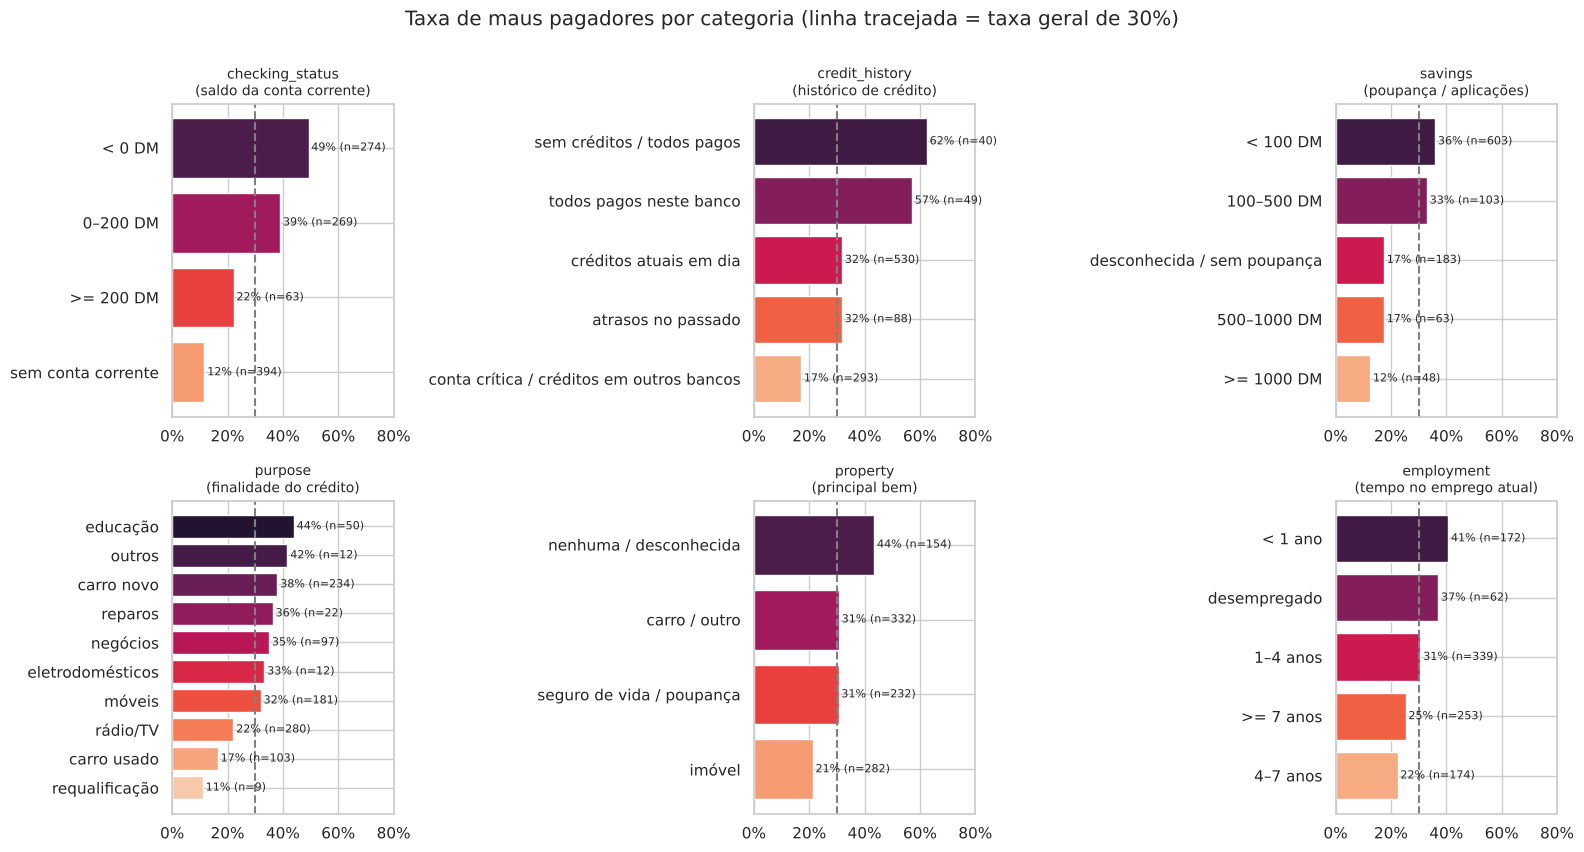

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat, ["checking_status", "credit_history", "savings", "purpose", "property", "employment"]):
    rate = df.groupby(col)["target"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(rate.index, rate["mean"], color=sns.color_palette("rocket_r", len(rate)))
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(m + .01, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
    ax.axvline(df["target"].mean(), ls="--", c="gray")
    ax.set_title(f"{col}\n({DESCR[col]})", fontsize=10); ax.set_xlim(0, .8)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
fig.suptitle("Taxa de maus pagadores por categoria (linha tracejada = taxa geral de 30%)", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "eda_categoricas.png", dpi=130, bbox_inches="tight"); plt.show()

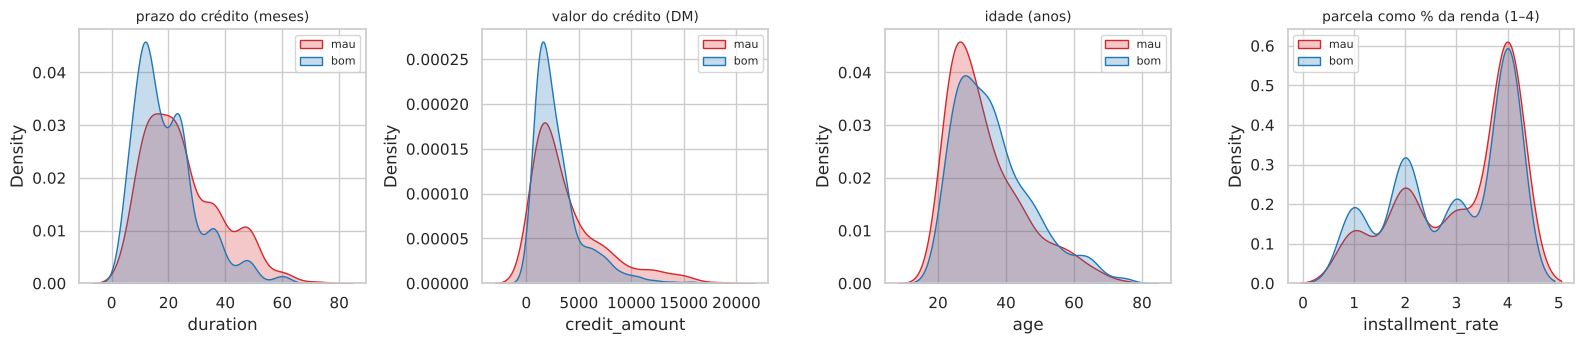

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(axes, ["duration", "credit_amount", "age", "installment_rate"]):
    sns.kdeplot(data=df, x=col, hue="target", common_norm=False, fill=True, ax=ax,
                palette={0: "tab:blue", 1: "tab:red"})
    ax.set_title(DESCR[col], fontsize=10)
    ax.legend(["mau", "bom"], fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "eda_numericas.png", dpi=130, bbox_inches="tight"); plt.show()

**Observações da EDA**
- **Sem valores ausentes nem duplicatas** — não é preciso imputação.
- **Desbalanceamento 70/30**: um modelo que diz “bom” para todos já acerta 70%. Por isso a acurácia
  sozinha é enganosa e usaremos ROC-AUC, recall, F1 e acurácia balanceada.
- **`checking_status` é o atributo mais discriminante na EDA**: saldo negativo → 49% de inadimplência; sem
  conta corrente → 12%.
- **Créditos mais longos e mais altos** concentram mais maus pagadores; clientes mais jovens também.
- **Achado contraintuitivo:** `credit_history = conta crítica` tem a *menor* taxa de inadimplência (17%).
  Explicações plausíveis: (i) *viés de seleção* — o banco só concedeu crédito a clientes “críticos” que
  tinham outras garantias; (ii) a codificação original deste dataset tem inconsistências documentadas
  (Grömping, 2019, *South German Credit Data: Correcting a Widely Used Data Set*). Guardamos isso para a
  discussão: **um modelo pode estar “certo” estatisticamente e ainda assim usar uma regra que não faz
  sentido de negócio** — e só a interpretabilidade revela isso.

# 2. Construção e treinamento dos modelos (Etapa 2)

## 2.1 Divisão treino/teste
**80% treino / 20% teste, estratificado pelo alvo** (`random_state=42`). A estratificação mantém a
proporção 70/30 nos dois conjuntos; 80/20 deixa 800 exemplos para treinar e ajustar hiperparâmetros
via validação cruzada, e 200 (60 maus pagadores) para a avaliação final. O conjunto de teste **não é
usado** em nenhuma decisão de modelagem.

In [7]:
X, y = df[FEATURES], df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("treino:", X_train.shape, "| maus pagadores:", f"{y_train.mean():.1%}")
print("teste :", X_test.shape, "| maus pagadores:", f"{y_test.mean():.1%}")

treino: (800, 20) | maus pagadores: 30.0%
teste : (200, 20) | maus pagadores: 30.0%


## 2.2 Pré-processamento — um por modelo, e por quê

Cada algoritmo tem premissas diferentes, então o pré-processamento foi desenhado **por modelo**, sempre
dentro de um `Pipeline` (o ajuste dos transformadores acontece só nos dados de treino de cada fold,
evitando *data leakage*).

| Modelo | Numéricas | Categóricas | Justificativa |
|---|---|---|---|
| **KNN** | `StandardScaler` | One-Hot | O KNN usa distância euclidiana: sem padronização, `credit_amount` (até 18 mil) dominaria `installment_rate` (1–4). One-hot evita impor uma ordem falsa entre categorias nominais. |
| **Naïve Bayes** | `KBinsDiscretizer` (quantis) | `OrdinalEncoder` | Usamos `CategoricalNB`: toda feature vira categórica e o modelo aprende **tabelas de probabilidade condicional P(valor \| classe)** — diretamente legíveis (exigência da Etapa 3). O `GaussianNB` suporia normalidade, falsa para `credit_amount` e `duration` (assimétricas, ver EDA). |
| **Árvore** | sem transformação | One-Hot | Árvores são invariantes à escala. One-hot faz cada nó perguntar “cliente tem *X*?”, o que gera regras legíveis. |

**Valores ausentes:** não há. **Outliers:** mantidos — valores altos de crédito são legítimos e informativos.

## 2.3 Ajuste de hiperparâmetros
`GridSearchCV` com validação cruzada estratificada de 5 folds no **treino**, otimizando o **F1 da classe
“mau pagador”**. Justificativa:
- o interesse do banco é *detectar* inadimplentes sem recusar todo mundo — o F1 equilibra recall e
  precisão dessa classe no limiar em que a decisão é de fato tomada;
- testamos antes otimizar ROC-AUC: o KNN escolheu k = 93, que ordena bem os clientes (AUC alto) mas, no
  limiar 0,5, quase nunca prevê “mau” (recall ≈ 3%) — um modelo inútil na prática. A acurácia teria o
  mesmo problema (favorece o “sempre bom”).

Na árvore, limitamos a profundidade a ≤ 5 de propósito: uma árvore de 15 níveis seria “interpretável”
só na teoria. Testamos também `class_weight="balanced"`, que compensa o desbalanceamento 70/30.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

knn_pipe = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), NUM),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])),
    ("clf", KNeighborsClassifier())])
knn_grid = {"clf__n_neighbors": list(range(3, 102, 2)), "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2]}

nb_pipe = Pipeline([
    ("prep", ColumnTransformer([("num", KBinsDiscretizer(encode="ordinal", strategy="quantile"), NUM),
                                ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)])),
    ("clf", CategoricalNB())])
nb_grid = {"prep__num__n_bins": [3, 4, 5], "clf__alpha": [0.1, 0.5, 1, 2, 5]}

dt_pipe = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", NUM),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])),
    ("clf", DecisionTreeClassifier(random_state=SEED))])
dt_grid = {"clf__max_depth": [2, 3, 4, 5], "clf__min_samples_leaf": [5, 10, 20, 30],
           "clf__criterion": ["gini", "entropy"], "clf__class_weight": [None, "balanced"]}

searches = {}
for name, pipe, grid in [("KNN", knn_pipe, knn_grid), ("Naïve Bayes", nb_pipe, nb_grid),
                         ("Árvore de Decisão", dt_pipe, dt_grid)]:
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    searches[name] = gs
    print(f"{name:18s} F1-CV = {gs.best_score_:.3f}  melhores parâmetros: {gs.best_params_}")

models = {n: gs.best_estimator_ for n, gs in searches.items()}
knn, nb, dt = models["KNN"], models["Naïve Bayes"], models["Árvore de Decisão"]

KNN                F1-CV = 0.457  melhores parâmetros: {'clf__n_neighbors': 5, 'clf__p': 1, 'clf__weights': 'distance'}


Naïve Bayes        F1-CV = 0.565  melhores parâmetros: {'clf__alpha': 1, 'prep__num__n_bins': 3}


Árvore de Decisão  F1-CV = 0.561  melhores parâmetros: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 3, 'clf__min_samples_leaf': 20}


## 2.4 Avaliação no conjunto de teste

Métricas reportadas (classe positiva = **mau pagador**):
- **Acurácia** — referência, mas enganosa com 70/30.
- **Precisão** — dos clientes que o modelo recusaria, quantos eram de fato maus.
- **Recall** — dos maus pagadores reais, quantos o modelo pegou (o erro mais caro para o banco).
- **F1** — equilíbrio entre precisão e recall.
- **Acurácia balanceada** e **ROC-AUC** — robustas ao desbalanceamento.
- **Custo** — a documentação do dataset define uma matriz de custo: aprovar um mau pagador custa **5**,
  recusar um bom custa **1**. É a métrica mais próxima do impacto real.

Incluímos um `DummyClassifier` (sempre “bom”) como linha de base.

In [9]:
def evaluate(model, X_, y_, threshold=0.5):
    p = model.predict_proba(X_)[:, 1]
    yp = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, yp).ravel()
    return {"Acurácia": accuracy_score(y_, yp), "Precisão": precision_score(y_, yp, zero_division=0),
            "Recall": recall_score(y_, yp), "F1": f1_score(y_, yp),
            "Acur. balanceada": balanced_accuracy_score(y_, yp), "ROC-AUC": roc_auc_score(y_, p),
            "Custo (5·FN + FP)": 5 * fn + fp}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in {"Baseline (sempre bom)": dummy, **models}.items()}).T
results.style.format({c: "{:.3f}" for c in results.columns if c != "Custo (5·FN + FP)"} | {"Custo (5·FN + FP)": "{:.0f}"}) \
       .background_gradient(cmap="Greens", subset=["F1", "ROC-AUC"])

,Acurácia,Precisão,Recall,F1,Acur. balanceada,ROC-AUC,Custo (5·FN + FP)
Baseline (sempre bom),0.700,0.000,0.000,0.000,0.500,0.500,300
KNN,0.730,0.575,0.383,0.460,0.631,0.749,202
Naïve Bayes,0.755,0.604,0.533,0.566,0.692,0.780,161
Árvore de Decisão,0.625,0.436,0.850,0.576,0.689,0.704,111


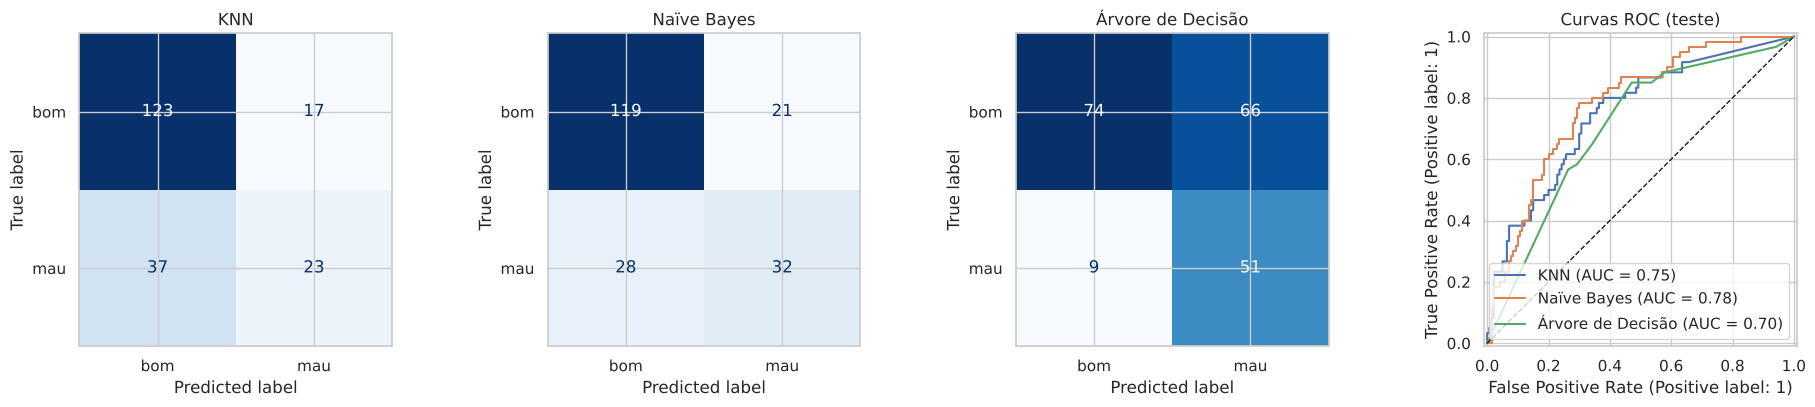

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, (n, m) in zip(axes[:3], models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["bom", "mau"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(n)
for n, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=n, ax=axes[3])
axes[3].plot([0, 1], [0, 1], "k--", lw=1); axes[3].set_title("Curvas ROC (teste)")
plt.tight_layout(); plt.savefig(FIG / "avaliacao.png", dpi=130, bbox_inches="tight"); plt.show()

### Limiar de decisão orientado a custo

Com custo 5:1, a teoria de decisão bayesiana indica recusar quando
P(mau) > 1/(1+5) ≈ **0,167**, e não 0,5. Mostramos o efeito — sem re-treinar nada — para evidenciar que
“o modelo” é também uma escolha de limiar, e essa escolha deve ser explicada ao usuário.

In [11]:
cost_tbl = pd.DataFrame({n: {**{f"{k} (lim. 0,5)": v for k, v in evaluate(m, X_test, y_test, 0.5).items() if k in ("Recall", "Precisão", "Custo (5·FN + FP)")},
                             **{f"{k} (lim. 1/6)": v for k, v in evaluate(m, X_test, y_test, 1/6).items() if k in ("Recall", "Precisão", "Custo (5·FN + FP)")}}
                         for n, m in models.items()}).T
cost_tbl.round(3)

,"Precisão (lim. 0,5)","Recall (lim. 0,5)","Custo (5·FN + FP) (lim. 0,5)",Precisão (lim. 1/6),Recall (lim. 1/6),Custo (5·FN + FP) (lim. 1/6)
KNN,0.575,0.383,202.0,0.378,0.900,119.0
Naïve Bayes,0.604,0.533,161.0,0.459,0.833,109.0
Árvore de Decisão,0.436,0.850,111.0,0.396,0.883,116.0


**Leitura dos resultados**
- Os três modelos superam claramente a linha de base (AUC 0,50; F1 0; custo 300). AUC entre 0,70 e 0,78
  e F1 entre 0,46 e 0,58 estão na faixa usual da literatura para este dataset — desempenho **suficiente
  para que a análise de interpretabilidade seja significativa**.
- **Naïve Bayes**: melhor AUC (0,78), melhor acurácia e melhor precisão — apesar da premissa “ingênua” de
  independência. Com 800 exemplos de treino, um modelo com poucos parâmetros generaliza bem.
- **Árvore de Decisão** (profundidade 3, pesos balanceados): menor AUC (0,70), mas maior recall (0,85) e
  menor custo no limiar 0,5. Os pesos balanceados a tornaram **conservadora**: recusa muitos bons
  clientes (precisão 0,44) para não deixar passar maus pagadores.
- **KNN** (k = 5): AUC intermediário, mas o pior F1 e recall (0,38): os vizinhos são majoritariamente
  “bons” (70% da base) e o KNN não tem como pesar as classes.
- Com o limiar de custo (1/6), os três modelos convergem para custos parecidos (≈ 110–120), com recall
  ≥ 0,83. Ou seja, **parte da diferença entre os modelos é escolha de limiar**, não de algoritmo.

# 3. Investigação da interpretabilidade (Etapa 3)

> *“Por que o modelo chegou a essa conclusão?”*

Respondemos em dois níveis:
- **Global** — quais variáveis o modelo usa, em geral.
- **Local** — por que *este* cliente específico foi classificado assim.

Para tornar a comparação concreta, escolhemos um **cliente-exemplo** do conjunto de teste: um mau pagador
real que os três modelos classificam como de alto risco. Ele será explicado por todas as técnicas.

In [12]:
proba_test = pd.DataFrame({n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}, index=X_test.index)
cand = proba_test[(y_test == 1) & (proba_test > 0.5).all(axis=1)]
ex_id = cand.mean(axis=1).sort_values().index[len(cand) // 2]   # caso "típico" entre os de alto risco
x_ex = X_test.loc[[ex_id]]
print(f"Cliente-exemplo: índice {ex_id} | rótulo real: {'mau' if y_test[ex_id] else 'bom'}")
print(proba_test.loc[ex_id].round(3).rename("P(mau pagador)").to_string())
x_ex.T.rename(columns={ex_id: "valor"}).assign(descrição=pd.Series(DESCR))

Cliente-exemplo: índice 832 | rótulo real: mau
KNN                  0.606
Naïve Bayes          0.874
Árvore de Decisão    0.721


,valor,descrição
checking_status,< 0 DM,saldo da conta corrente
duration,45,prazo do crédito (meses)
credit_history,sem créditos / todos pagos,histórico de crédito
purpose,negócios,finalidade do crédito
credit_amount,11816,valor do crédito (DM)
savings,< 100 DM,poupança / aplicações
employment,>= 7 anos,tempo no emprego atual
installment_rate,2,parcela como % da renda (1–4)
personal_status_sex,masc. solteiro,sexo e estado civil
other_debtors,nenhum,outros devedores / fiadores


## 3.1 Árvore de Decisão — interpretabilidade intrínseca

A árvore é um modelo **transparente**: a própria estrutura é a explicação. Analisamos:
1. o desenho da árvore (regras);
2. a importância das features por redução de impureza;
3. o caminho de decisão percorrido pelo cliente-exemplo.

profundidade = 3 | folhas = 8


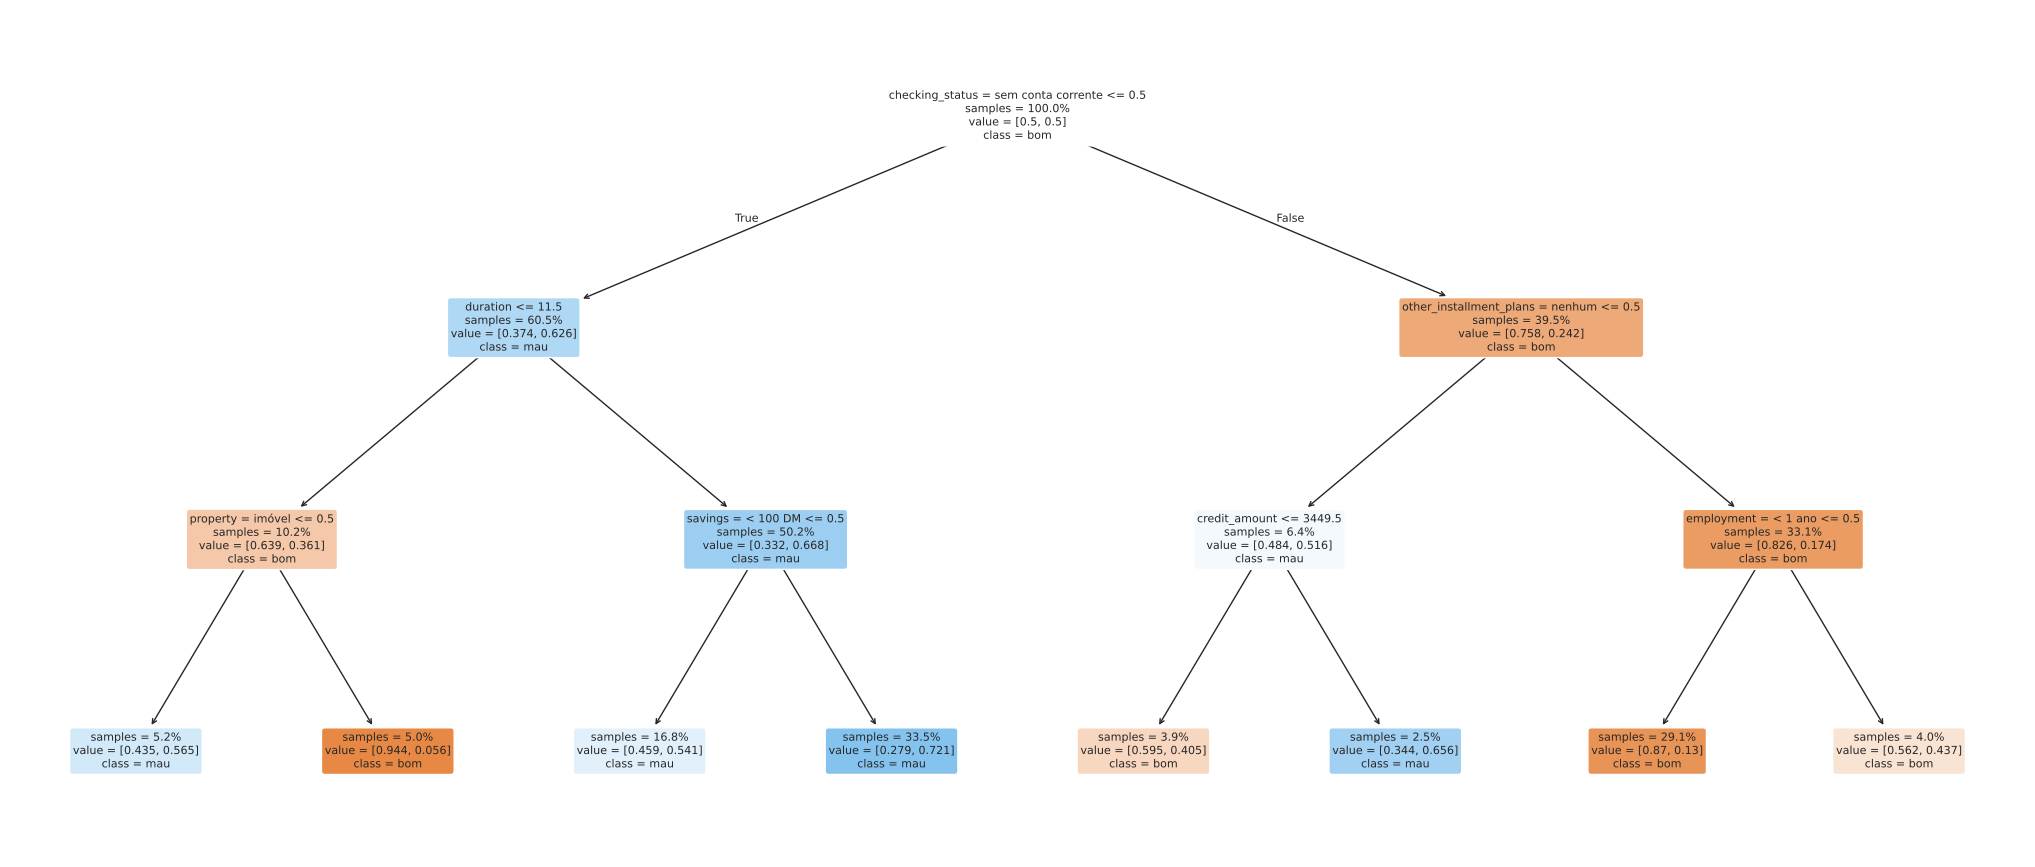

In [13]:
dt_prep, dt_clf = dt.named_steps["prep"], dt.named_steps["clf"]

def readable_names(prep):
    # nomes 'checking_status = < 0 DM' em vez de 'cat__checking_status_A11'
    names, origin = [], []
    for name, trans, cols in prep.transformers_:
        if name == "num":
            names += cols; origin += cols
        elif name == "cat":
            for c, cats in zip(cols, trans.categories_):
                names += [f"{c} = {v}" for v in cats]; origin += [c] * len(cats)
    return names, origin

dt_names, dt_origin = readable_names(dt_prep)
print(f"profundidade = {dt_clf.get_depth()} | folhas = {dt_clf.get_n_leaves()}")

fig, ax = plt.subplots(figsize=(26, 11))
plot_tree(dt_clf, feature_names=dt_names, class_names=["bom", "mau"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=8, ax=ax)
plt.savefig(FIG / "arvore.png", dpi=110, bbox_inches="tight"); plt.show()

In [14]:
print(export_text(dt_clf, feature_names=dt_names, show_weights=False, decimals=0))

|--- checking_status = sem conta corrente <= 0
|   |--- duration <= 12
|   |   |--- property = imóvel <= 0
|   |   |   |--- class: 1
|   |   |--- property = imóvel >  0
|   |   |   |--- class: 0
|   |--- duration >  12
|   |   |--- savings = < 100 DM <= 0
|   |   |   |--- class: 1
|   |   |--- savings = < 100 DM >  0
|   |   |   |--- class: 1
|--- checking_status = sem conta corrente >  0
|   |--- other_installment_plans = nenhum <= 0
|   |   |--- credit_amount <= 3450
|   |   |   |--- class: 0
|   |   |--- credit_amount >  3450
|   |   |   |--- class: 1
|   |--- other_installment_plans = nenhum >  0
|   |   |--- employment = < 1 ano <= 0
|   |   |   |--- class: 0
|   |   |--- employment = < 1 ano >  0
|   |   |   |--- class: 0



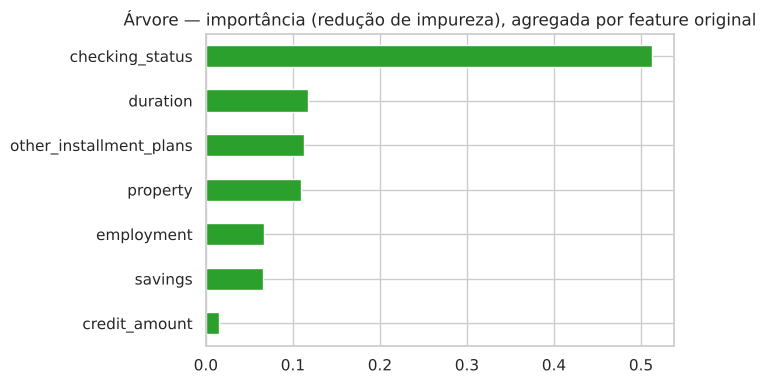

Features nunca usadas pela árvore: ['credit_history', 'purpose', 'installment_rate', 'other_debtors', 'personal_status_sex', 'residence_since', 'age', 'housing', 'existing_credits', 'job', 'num_dependents', 'telephone', 'foreign_worker']


In [15]:
imp_dt = (pd.Series(dt_clf.feature_importances_, index=dt_origin).groupby(level=0).sum()
            .reindex(FEATURES).fillna(0).sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(7, 4))
imp_dt[imp_dt > 0].sort_values().plot.barh(ax=ax, color="tab:green")
ax.set_title("Árvore — importância (redução de impureza), agregada por feature original")
plt.tight_layout(); plt.savefig(FIG / "arvore_importancia.png", dpi=130, bbox_inches="tight"); plt.show()
print("Features nunca usadas pela árvore:", list(imp_dt[imp_dt == 0].index))

In [16]:
# caminho de decisão do cliente-exemplo
Xt_ex = dt_prep.transform(x_ex)
node_ids = dt_clf.decision_path(Xt_ex).indices
tree = dt_clf.tree_
print(f"Caminho de decisão do cliente {ex_id}:\n")
for nid in node_ids:
    if tree.children_left[nid] == -1:
        v = tree.value[nid][0]; v = v / v.sum()
        print(f"  FOLHA {nid}: P(mau) = {v[1]:.2f}  ({tree.n_node_samples[nid]} clientes de treino nesta folha)")
        break
    f, thr = tree.feature[nid], tree.threshold[nid]
    val = Xt_ex[0, f]
    name = dt_names[f]
    if " = " in name:   # feature one-hot
        cond = f"{name}? {'SIM' if val > thr else 'NÃO'}"
    else:
        cond = f"{name} = {val:.0f} {'>' if val > thr else '<='} {thr:.1f}"
    print(f"  nó {nid:2d}: {cond}")

Caminho de decisão do cliente 832:

  nó  0: checking_status = sem conta corrente? NÃO
  nó  1: duration = 45 > 11.5
  nó  5: savings = < 100 DM? SIM
  FOLHA 7: P(mau) = 0.72  (268 clientes de treino nesta folha)


**O que a árvore nos diz**
- A **raiz** separa clientes *sem conta corrente* dos demais — exatamente o atributo mais discriminante na
  EDA. A árvore “redescobriu” a principal regra de negócio sem ninguém informá-la.
- O modelo inteiro cabe em **8 regras**. Lendo a árvore: *quem tem conta corrente* (qualquer saldo) e
  pede crédito por **mais de 12 meses** é classificado como “mau” — com ou sem poupança. Quem *não tem
  conta corrente* só é “mau” se já tem **parcelamento em banco/loja** e pede **mais de 3.450 DM**.
- Em seguida à raiz aparecem **prazo (`duration`)**, **poupança (`savings`)**, **outros parcelamentos**,
  **bens (`property`)** e **valor (`credit_amount`)** — variáveis financeiras coerentes com risco.
- **13 das 20 features nunca são usadas** — entre elas `credit_history`, idade, sexo/estado civil e
  trabalhador estrangeiro. A árvore é esparsa por construção, o que torna a auditoria de atributos
  sensíveis trivial.
- Duas divisões terminam em folhas da **mesma classe** (`savings` → ambas “mau”; `employment` → ambas
  “bom”): refinam a probabilidade, mas não mudam a decisão — detalhe que só se percebe olhando a estrutura.
- O caminho do cliente-exemplo é uma **explicação completa e fiel**: três perguntas que qualquer analista
  verifica (“tem conta corrente com saldo negativo, prazo de 45 meses e poupança < 100 DM”).
- Os valores (`value`) do desenho estão ponderados pelos pesos balanceados — por isso a raiz mostra
  [0,5; 0,5], e não 70/30.

**Limitações:** a regra é **grosseira** — todo cliente com conta corrente e prazo > 12 meses recebe a
mesma resposta, o que explica o recall alto e a precisão baixa. A importância por impureza é calculada no
treino e favorece variáveis contínuas; árvores são **instáveis** (outra amostra, outra árvore) e só são
legíveis enquanto rasas — o que custou desempenho (menor AUC dos três).

## 3.2 Naïve Bayes — probabilidades condicionais

O `CategoricalNB` classifica pelo teorema de Bayes assumindo independência condicional:

$$P(\text{mau}\mid x) \propto P(\text{mau})\prod_{i} P(x_i \mid \text{mau})$$

Tomando a razão entre as classes em escala log, a decisão vira uma **soma aditiva de evidências**:

$$\log\frac{P(\text{mau}\mid x)}{P(\text{bom}\mid x)} = \underbrace{\log\frac{P(\text{mau})}{P(\text{bom})}}_{\text{a priori}} + \sum_i \underbrace{\log\frac{P(x_i\mid \text{mau})}{P(x_i\mid \text{bom})}}_{\text{evidência da feature } i}$$

Cada termo é a contribuição exata da feature *i*: positivo empurra para “mau”, negativo para “bom”.
Isso torna o NB **interpretável de forma exata**, sem precisar de ferramentas externas.

In [17]:
nb_prep, nb_clf = nb.named_steps["prep"], nb.named_steps["clf"]
kb = nb_prep.named_transformers_["num"]
ordenc = nb_prep.named_transformers_["cat"]

# rótulos legíveis para os valores de cada feature (faixas para numéricas)
value_labels = {}
for c, edges in zip(NUM, kb.bin_edges_):
    e = np.round(edges, 0)
    value_labels[c] = [f"[{e[i]:.0f}, {e[i+1]:.0f})" for i in range(len(e) - 1)]
for c, cats in zip(CAT, ordenc.categories_):
    value_labels[c] = list(cats)
nb_feats = NUM + CAT   # ordem das colunas na saída do ColumnTransformer

print("Prioris aprendidas:", dict(zip(["bom", "mau"], np.exp(nb_clf.class_log_prior_).round(3))))

def cond_table(feat):
    j = nb_feats.index(feat)
    p = np.exp(nb_clf.feature_log_prob_[j])          # shape (2 classes, n_valores)
    labels = value_labels[feat][: p.shape[1]]
    t = pd.DataFrame({"P(valor | bom)": p[0], "P(valor | mau)": p[1]}, index=labels)
    t["log-razão (evidência p/ mau)"] = np.log(t["P(valor | mau)"] / t["P(valor | bom)"])
    t.index.name = feat
    return t.round(3)

for f in ["checking_status", "credit_history", "duration"]:
    display(cond_table(f))

Prioris aprendidas: {'bom': np.float64(0.7), 'mau': np.float64(0.3)}


,P(valor | bom),P(valor | mau),log-razão (evidência p/ mau)
checking_status,,,
0–200 DM,0.232,0.348,0.405
< 0 DM,0.204,0.434,0.756
>= 200 DM,0.069,0.057,-0.187
sem conta corrente,0.495,0.160,-1.130


,P(valor | bom),P(valor | mau),log-razão (evidência p/ mau)
credit_history,,,
atrasos no passado,0.088,0.098,0.102
conta crítica / créditos em outros bancos,0.352,0.176,-0.697
créditos atuais em dia,0.501,0.551,0.095
sem créditos / todos pagos,0.023,0.082,1.266
todos pagos neste banco,0.035,0.094,0.975


,P(valor | bom),P(valor | mau),log-razão (evidência p/ mau)
duration,,,
"[4, 12)",0.222,0.086,-0.944
"[12, 24)",0.412,0.391,-0.053
"[24, 60)",0.366,0.523,0.357


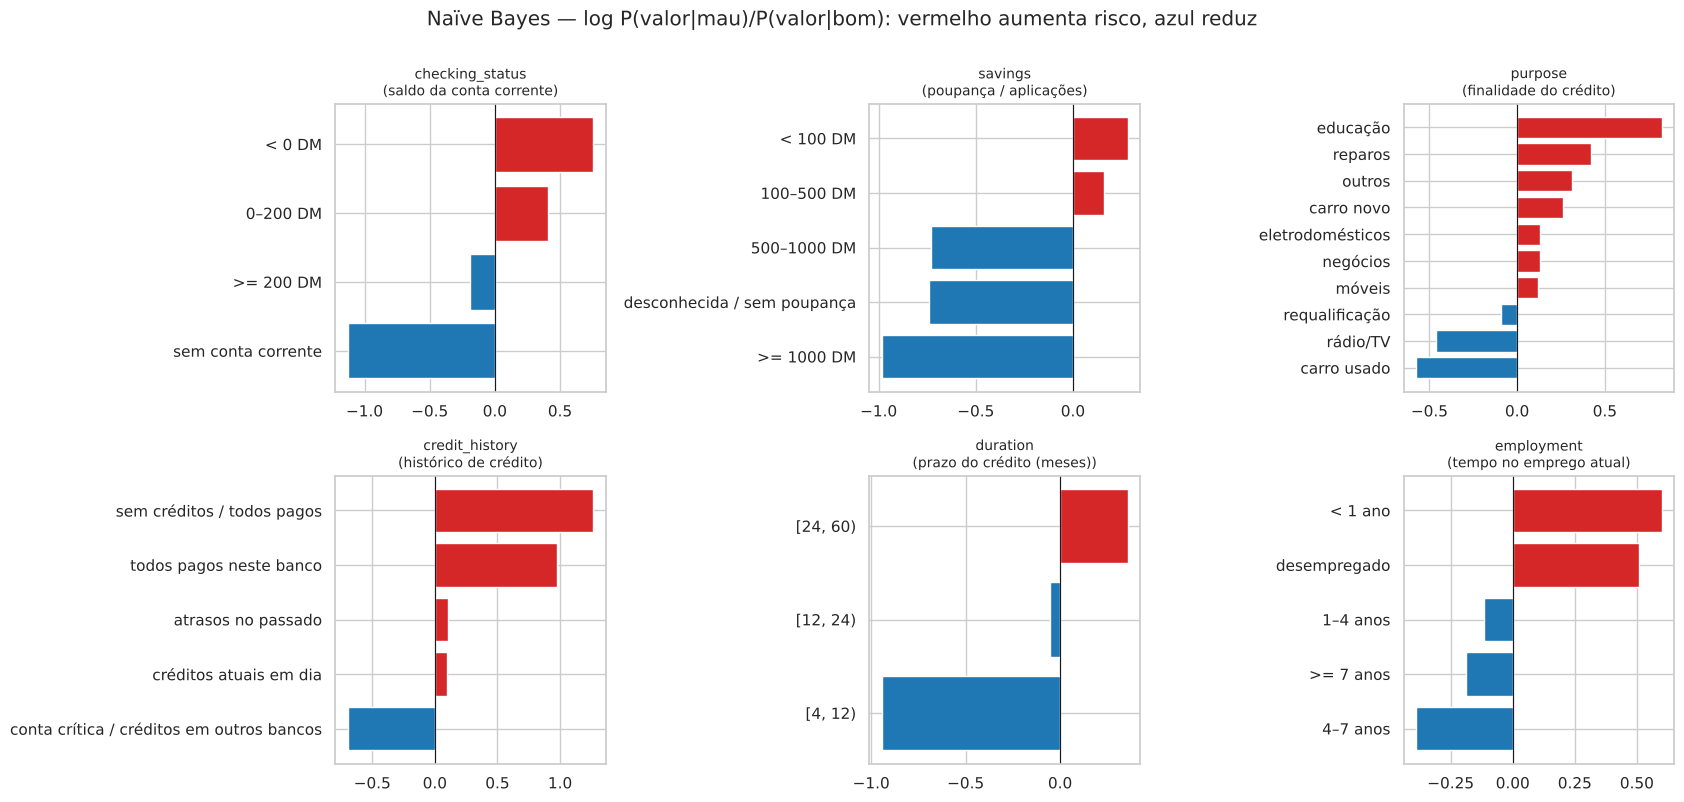

In [18]:
# Visão global: log-razão de verossimilhança para cada valor das features mais influentes
contrib = []
Xt_test = nb_prep.transform(X_test).astype(int)
llr = [nb_clf.feature_log_prob_[j][1] - nb_clf.feature_log_prob_[j][0] for j in range(len(nb_feats))]
contrib_test = pd.DataFrame({f: llr[j][Xt_test[:, j]] for j, f in enumerate(nb_feats)}, index=X_test.index)
imp_nb = contrib_test.abs().mean().reindex(FEATURES).sort_values(ascending=False)

top = imp_nb.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, f in zip(axes.flat, top):
    t = cond_table(f)["log-razão (evidência p/ mau)"].sort_values()
    ax.barh(t.index.astype(str), t.values, color=["tab:red" if v > 0 else "tab:blue" for v in t.values])
    ax.axvline(0, c="k", lw=.8); ax.set_title(f"{f}\n({DESCR[f]})", fontsize=10)
fig.suptitle("Naïve Bayes — log P(valor|mau)/P(valor|bom): vermelho aumenta risco, azul reduz", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "nb_log_razao.png", dpi=130, bbox_inches="tight"); plt.show()

log-odds a priori = -0.847  |  soma das evidências = +2.781  |  total = +1.934
P(mau) = 1/(1+e^-total) = 0.874   (predict_proba: 0.874)


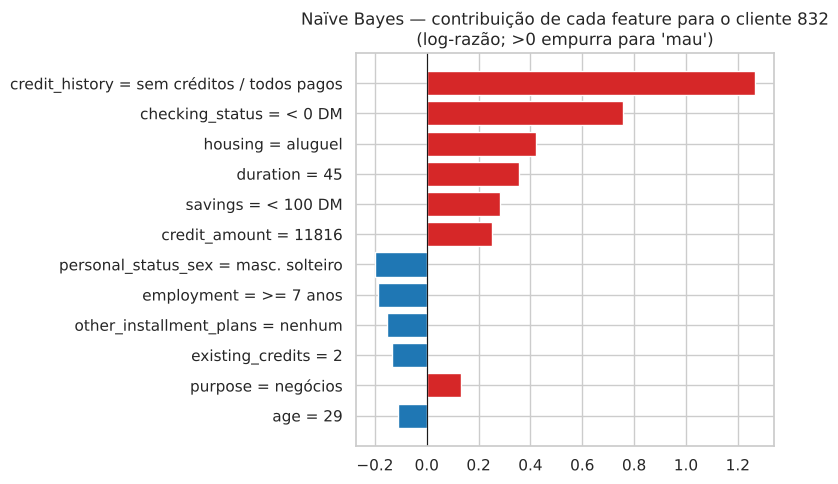

In [19]:
# Explicação local exata do cliente-exemplo
row = contrib_test.loc[ex_id].reindex(FEATURES)
prior = nb_clf.class_log_prior_[1] - nb_clf.class_log_prior_[0]
total = prior + row.sum()
print(f"log-odds a priori = {prior:+.3f}  |  soma das evidências = {row.sum():+.3f}  |  total = {total:+.3f}")
print(f"P(mau) = 1/(1+e^-total) = {1/(1+np.exp(-total)):.3f}   (predict_proba: {nb.predict_proba(x_ex)[0,1]:.3f})")

lab = [f"{f} = {x_ex.iloc[0][f]}" for f in FEATURES]
s = pd.Series(row.values, index=lab).sort_values(key=np.abs).tail(12)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(s.index, s.values, color=["tab:red" if v > 0 else "tab:blue" for v in s.values])
ax.axvline(0, c="k", lw=.8)
ax.set_title(f"Naïve Bayes — contribuição de cada feature para o cliente {ex_id}\n(log-razão; >0 empurra para 'mau')")
plt.tight_layout(); plt.savefig(FIG / "nb_local.png", dpi=130, bbox_inches="tight"); plt.show()

**O que as probabilidades condicionais nos dizem**
- `checking_status` é a evidência mais forte: “saldo < 0 DM” tem log-razão +0,76 — multiplica a chance
  de “mau” por e^0,76 ≈ 2,1; “sem conta corrente” tem −1,13 (divide a chance por ≈ 3,1).
- `credit_history`: “sem créditos / todos pagos” aumenta o risco; “conta crítica” *reduz* — o mesmo achado
  contraintuitivo da EDA. O NB **aprende fielmente o padrão dos dados, inclusive o que parece errado**, e
  torna isso visível em uma tabela.
- `duration` (3 faixas por quantis): até 12 meses reduz o risco (−0,94), acima de 24 meses aumenta (+0,36)
  — efeito monotônico e coerente.
- A decomposição local **reconstrói exatamente** a probabilidade do modelo (−0,85 de priori + 2,78 de
  evidências = 1,93 → P(mau) = 0,874, igual ao `predict_proba`). É uma explicação fiel, não uma
  aproximação.

**Limitações:** a premissa de independência é falsa (ex.: `duration` e `credit_amount` são correlacionadas),
então evidências correlacionadas são **contadas em dobro** e as probabilidades ficam mal calibradas
(extremas). A discretização perde informação dentro de cada faixa. E o NB não captura interações
(“prazo longo *só é* arriscado sem poupança”), que a árvore captura.

## 3.3 KNN — o modelo “caixa-preta” do trio

### Por que o KNN é difícil de interpretar diretamente
- **Não há modelo aprendido**: não existem coeficientes, regras ou probabilidades por feature. A “decisão”
  é a votação dos *k* vizinhos mais próximos em um espaço de ~60 dimensões (após one-hot).
- A explicação natural — “estes são os clientes parecidos com você” — **não diz quais características
  pesaram**. Dois vizinhos podem estar próximos por razões completamente diferentes.
- A noção de “proximidade” depende de decisões de pré-processamento (escala, one-hot): uma categoria
  diferente conta como distância ≈ 1,41 padronizada, o que é arbitrário.
- Em alta dimensão as distâncias tendem a se concentrar (*maldição da dimensionalidade*), e os vizinhos
  ficam “igualmente distantes”.

Começamos pela explicação nativa (por exemplos) e depois aplicamos **SHAP** e **LIME**.

In [20]:
knn_prep, knn_clf = knn.named_steps["prep"], knn.named_steps["clf"]
dist, idx = knn_clf.kneighbors(knn_prep.transform(x_ex), n_neighbors=knn_clf.n_neighbors)
neigh = X_train.iloc[idx[0]].assign(distância=dist[0].round(2), rótulo=y_train.iloc[idx[0]].map({0: "bom", 1: "mau"}).values)
print(f"k = {knn_clf.n_neighbors}, pesos = {knn_clf.weights}, métrica p = {knn_clf.p}")
print(f"Vizinhos 'maus': {(neigh['rótulo'] == 'mau').sum()} de {len(neigh)}  →  P(mau) = {knn.predict_proba(x_ex)[0,1]:.3f}")
show = ["checking_status", "duration", "credit_amount", "credit_history", "savings", "purpose", "age", "distância", "rótulo"]
pd.concat([x_ex.assign(distância=0.0, rótulo="(cliente-exemplo)")[show], neigh[show].head(8)])

k = 5, pesos = distance, métrica p = 1
Vizinhos 'maus': 3 de 5  →  P(mau) = 0.606


,checking_status,duration,credit_amount,credit_history,savings,purpose,age,distância,rótulo
832,< 0 DM,45,11816,sem créditos / todos pagos,< 100 DM,negócios,29,0.00,(cliente-exemplo)
242,< 0 DM,48,4605,sem créditos / todos pagos,< 100 DM,carro usado,24,13.02,mau
973,< 0 DM,60,7297,créditos atuais em dia,< 100 DM,negócios,36,13.14,mau
63,0–200 DM,48,14421,sem créditos / todos pagos,< 100 DM,negócios,25,13.16,mau
202,sem conta corrente,27,5117,atrasos no passado,< 100 DM,negócios,26,13.19,bom
17,< 0 DM,30,8072,sem créditos / todos pagos,desconhecida / sem poupança,negócios,25,13.70,bom


A tabela mostra *quem* são os vizinhos, mas não responde *por que* o risco é alto. Vemos vizinhos com
`checking_status`, prazos e finalidades variados — não fica claro qual atributo determinou a votação.
Precisamos de técnicas **agnósticas ao modelo**.

### Configuração do SHAP e do LIME no espaço das features originais
Aplicamos as ferramentas sobre as **20 features originais** (não sobre as ~60 colunas one-hot). Assim
a explicação fala a língua do negócio (“`savings` aumentou o risco”) e é comparável entre os três modelos.
Para isso, codificamos cada categoria como inteiro e passamos ao explicador uma função que decodifica e
chama o pipeline completo.

In [21]:
# codificação inteira das categóricas, só para os explicadores (os modelos continuam recebendo o DataFrame original)
cat_levels = {c: sorted(df[c].unique()) for c in CAT}
def encode(Xdf):
    Z = Xdf[FEATURES].copy()
    for c in CAT:
        Z[c] = Z[c].map({v: i for i, v in enumerate(cat_levels[c])})
    return Z.astype(float).values
def decode(Z):
    D = pd.DataFrame(np.asarray(Z, dtype=float), columns=FEATURES)
    for c in CAT:
        D[c] = np.array(cat_levels[c], dtype=object)[np.clip(np.rint(D[c]).astype(int), 0, len(cat_levels[c]) - 1)]
    for c in NUM:
        D[c] = D[c].round().astype(int)
    return D
def proba_fn(model):
    return lambda Z: model.predict_proba(decode(Z))[:, 1]

Z_train, Z_test = encode(X_train), encode(X_test)
background = shap.sample(Z_train, 50, random_state=SEED)      # 50 clientes de referência
explain_ids = np.random.RandomState(SEED).choice(len(Z_test), 100, replace=False)
if X_test.index.get_loc(ex_id) not in explain_ids:
    explain_ids[0] = X_test.index.get_loc(ex_id)
Z_explain = Z_test[explain_ids]
X_explain = X_test.iloc[explain_ids]

### SHAP (SHapley Additive exPlanations)
O SHAP distribui a previsão entre as features segundo os **valores de Shapley** da teoria dos jogos:
cada feature recebe sua contribuição média sobre todas as coalizões possíveis de features. Propriedades:
as contribuições **somam exatamente** a diferença entre a previsão e a média (eficiência), e features
irrelevantes recebem zero.

Como o KNN não tem estrutura explorável, usamos o `KernelExplainer` (agnóstico), com 50 clientes de
referência e 100 clientes de teste explicados. Usamos o mesmo explicador para os três modelos, para
comparar na Etapa 4.

In [22]:
shap_values = {}
for name, m in models.items():
    expl = shap.KernelExplainer(proba_fn(m), background)
    sv = expl.shap_values(Z_explain, nsamples=500, silent=True)
    shap_values[name] = shap.Explanation(values=sv, base_values=np.full(len(sv), expl.expected_value),
                                         data=X_explain.values, feature_names=FEATURES)
    print(f"{name}: SHAP calculado — valor base E[P(mau)] = {expl.expected_value:.3f}")

KNN: SHAP calculado — valor base E[P(mau)] = 0.420


Naïve Bayes: SHAP calculado — valor base E[P(mau)] = 0.337


Árvore de Decisão: SHAP calculado — valor base E[P(mau)] = 0.500


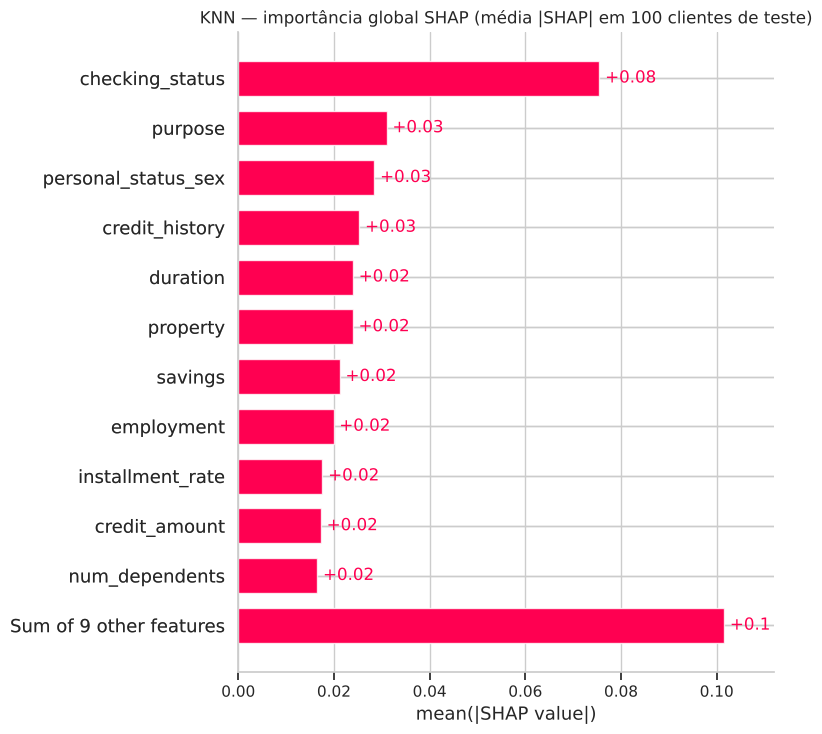

In [23]:
sv_knn = shap_values["KNN"]
fig = plt.figure(figsize=(8, 6))
shap.plots.bar(sv_knn, max_display=12, show=False)
plt.title("KNN — importância global SHAP (média |SHAP| em 100 clientes de teste)")
plt.tight_layout(); plt.savefig(FIG / "knn_shap_global.png", dpi=130, bbox_inches="tight"); plt.show()

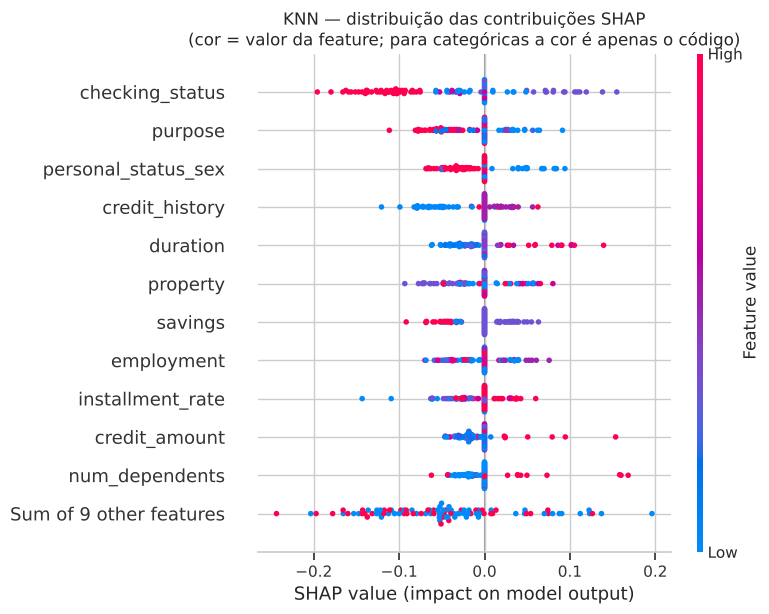

In [24]:
# beeswarm só faz sentido de cor para numéricas; mostramos a dispersão das contribuições
fig = plt.figure(figsize=(9, 6))
Zcolor = shap.Explanation(values=sv_knn.values, base_values=sv_knn.base_values, data=Z_explain, feature_names=FEATURES)
shap.plots.beeswarm(Zcolor, max_display=12, show=False)
plt.title("KNN — distribuição das contribuições SHAP\n(cor = valor da feature; para categóricas a cor é apenas o código)")
plt.tight_layout(); plt.savefig(FIG / "knn_shap_beeswarm.png", dpi=130, bbox_inches="tight"); plt.show()

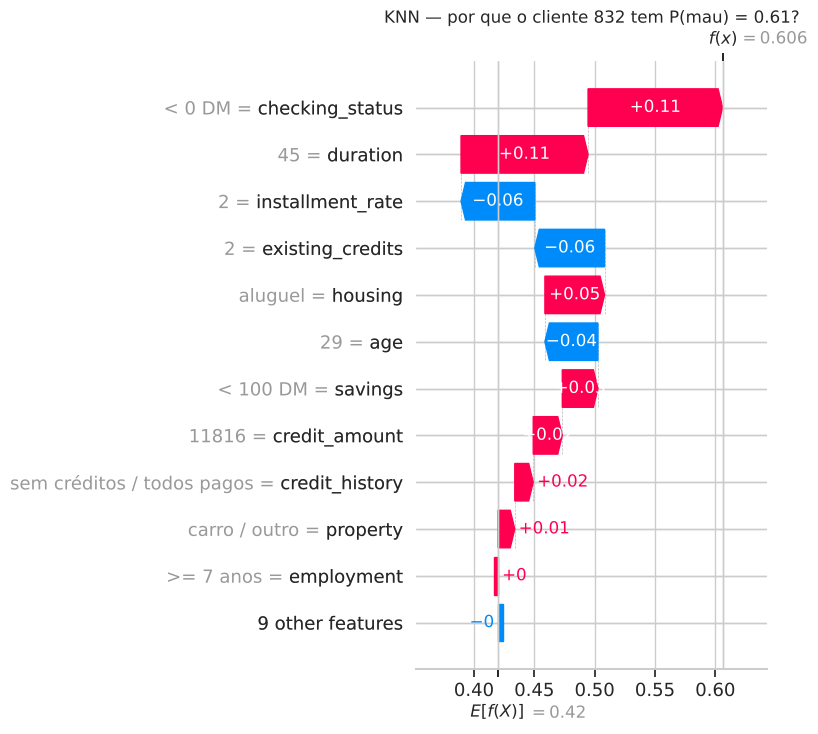

In [25]:
pos = list(explain_ids).index(X_test.index.get_loc(ex_id))
fig = plt.figure()
shap.plots.waterfall(sv_knn[pos], max_display=12, show=False)
plt.title(f"KNN — por que o cliente {ex_id} tem P(mau) = {knn.predict_proba(x_ex)[0,1]:.2f}?")
plt.tight_layout(); plt.savefig(FIG / "knn_shap_local.png", dpi=130, bbox_inches="tight"); plt.show()

### LIME (Local Interpretable Model-agnostic Explanations)
O LIME gera perturbações em torno do cliente, consulta o modelo e ajusta um **modelo linear local**
ponderado pela proximidade. Os coeficientes desse modelo substituto são a explicação. Diferenças em
relação ao SHAP: é uma aproximação *local* sem garantia de aditividade, e depende de parâmetros
(largura do kernel, discretização), podendo variar entre execuções.

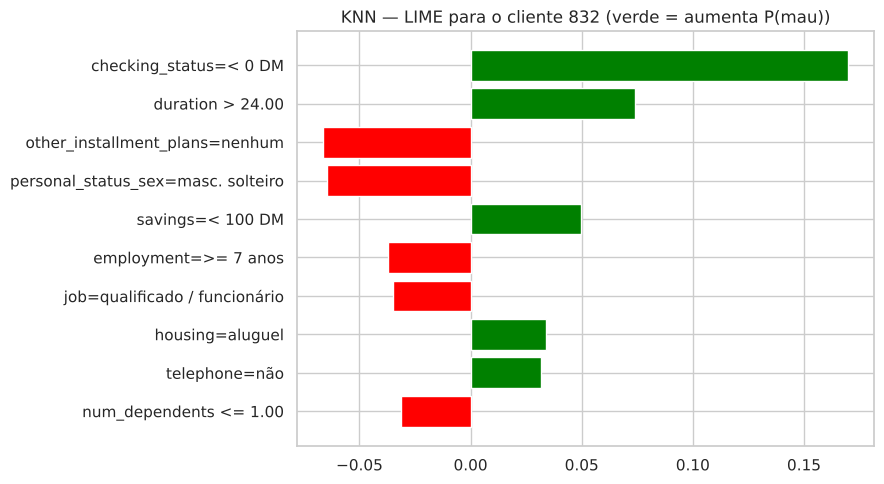

R² do modelo linear local: 0.187


In [26]:
lime_explainer = LimeTabularExplainer(
    Z_train, feature_names=FEATURES, class_names=["bom", "mau"],
    categorical_features=[FEATURES.index(c) for c in CAT],
    categorical_names={FEATURES.index(c): cat_levels[c] for c in CAT},
    discretize_continuous=True, random_state=SEED)

def lime_explain(model, num_features=10, seed=SEED):
    lime_explainer.random_state = np.random.RandomState(seed)
    two_cols = lambda Z: np.column_stack([1 - proba_fn(model)(Z), proba_fn(model)(Z)])
    return lime_explainer.explain_instance(encode(x_ex)[0], two_cols, num_features=num_features, num_samples=5000)

lime_knn = lime_explain(knn)
fig = lime_knn.as_pyplot_figure(label=1)
fig.set_size_inches(9, 5); plt.title(f"KNN — LIME para o cliente {ex_id} (verde = aumenta P(mau))")
plt.tight_layout(); plt.savefig(FIG / "knn_lime_local.png", dpi=130, bbox_inches="tight"); plt.show()
print(f"R² do modelo linear local: {lime_knn.score:.3f}")

In [27]:
# Estabilidade do LIME: mesma instância, sementes diferentes
runs = {f"semente {s}": dict(lime_explain(knn, seed=s).as_list(label=1)) for s in [0, 1, 2, 3, 4]}
stab = pd.DataFrame(runs).fillna(0)
stab.loc[stab.abs().mean(axis=1).sort_values(ascending=False).index].head(10).round(3)

,semente 0,semente 1,semente 2,semente 3,semente 4
checking_status=< 0 DM,0.162,0.174,0.172,0.169,0.171
other_installment_plans=nenhum,-0.067,-0.066,-0.077,-0.079,-0.083
duration > 24.00,0.063,0.072,0.076,0.064,0.062
personal_status_sex=masc. solteiro,-0.058,-0.063,-0.059,-0.063,-0.066
savings=< 100 DM,0.057,0.059,0.051,0.060,0.054
installment_rate <= 2.00,-0.044,-0.043,-0.041,-0.034,-0.038
telephone=não,0.039,0.034,0.047,0.040,0.036
housing=aluguel,0.047,0.040,0.051,0.000,0.051
num_dependents <= 1.00,0.000,-0.046,-0.044,-0.057,-0.037
credit_history=sem créditos / todos pagos,0.034,0.000,0.043,0.031,0.000


**O que SHAP e LIME revelaram sobre o KNN**
- Globalmente, o KNN depende sobretudo de `checking_status`, `purpose`, **`personal_status_sex`**,
  `credit_history` e `duration`. **Sem as ferramentas, isso era invisível**: o KNN não oferece nenhuma
  importância nativa.
- **Achado crítico:** sexo/estado civil é a **3ª** feature mais importante do KNN no SHAP (e a 2ª na
  permutação), enquanto a árvore nem a usa e o NB a coloca em 10º. Causa provável: com one-hot +
  distância, toda feature categórica pesa igual na distância — o KNN não “sabe” que essa variável é pouco
  informativa, e ela passa a definir quem são os vizinhos. Um atributo sensível influenciando a decisão
  por um *artefato do pré-processamento* — algo que só a interpretabilidade revelou.
- Localmente, SHAP e LIME **concordam no principal** (saldo < 0 DM, prazo longo e poupança < 100 DM
  aumentam o risco do cliente-exemplo), mas **divergem nos fatores secundários**: o SHAP destaca
  `installment_rate` e `existing_credits`; o LIME, `other_installment_plans` e `personal_status_sex`.
- Neste caso o LIME foi **estável entre sementes** nas principais features, mas o **R² do modelo linear
  local é baixo (≈ 0,19)**: a reta explica pouco do comportamento do KNN em volta do cliente, então a
  explicação é pouco fiel. O SHAP tem garantias teóricas, mas é **muito mais caro** (milhares de chamadas
  ao modelo por cliente).
- **Ressalva importante:** SHAP e LIME explicam o *comportamento* do modelo, não o seu *mecanismo*. São
  aproximações *post-hoc* que dependem do conjunto de referência e de como as perturbações são geradas
  (ex.: perturbar features de forma independente cria clientes irreais, como “crédito de 15 mil por 4 meses”).

## 3.4 Ferramentas agnósticas aplicadas aos três modelos

Para comparar os modelos em igualdade de condições, aplicamos aos três:
- **Importância por permutação** (scikit-learn): embaralha uma feature no **teste** e mede a queda de ROC-AUC.
  Mede o quanto o *desempenho* depende da feature. 30 repetições.
- **SHAP** (já calculado acima): mede o quanto a *previsão* depende da feature.

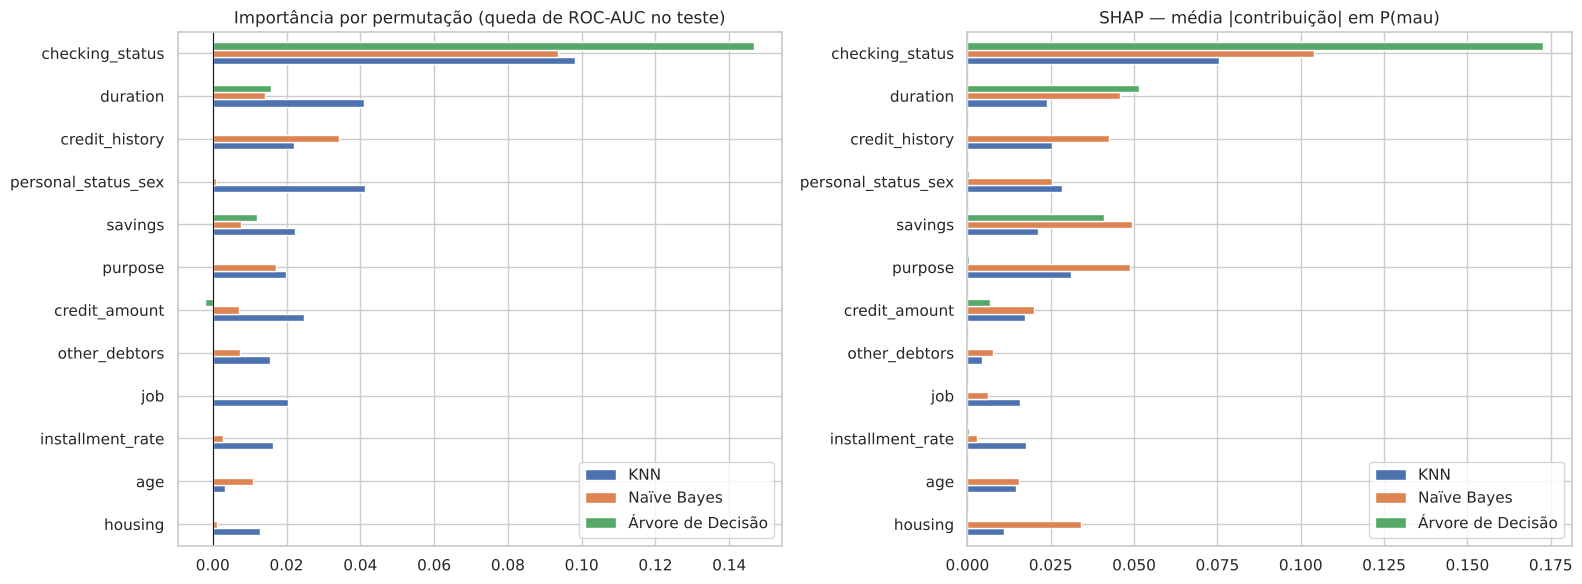

In [28]:
perm = {}
for name, m in models.items():
    r = permutation_importance(m, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=FEATURES)
perm = pd.DataFrame(perm)
shap_imp = pd.DataFrame({n: np.abs(sv.values).mean(axis=0) for n, sv in shap_values.items()}, index=FEATURES)

order = perm.mean(axis=1).sort_values(ascending=False).index[:12]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
perm.loc[order[::-1]].plot.barh(ax=axes[0]); axes[0].set_title("Importância por permutação (queda de ROC-AUC no teste)")
axes[0].axvline(0, c="k", lw=.8)
shap_imp.loc[order[::-1]].plot.barh(ax=axes[1]); axes[1].set_title("SHAP — média |contribuição| em P(mau)")
plt.tight_layout(); plt.savefig(FIG / "agnosticas_3modelos.png", dpi=130, bbox_inches="tight"); plt.show()

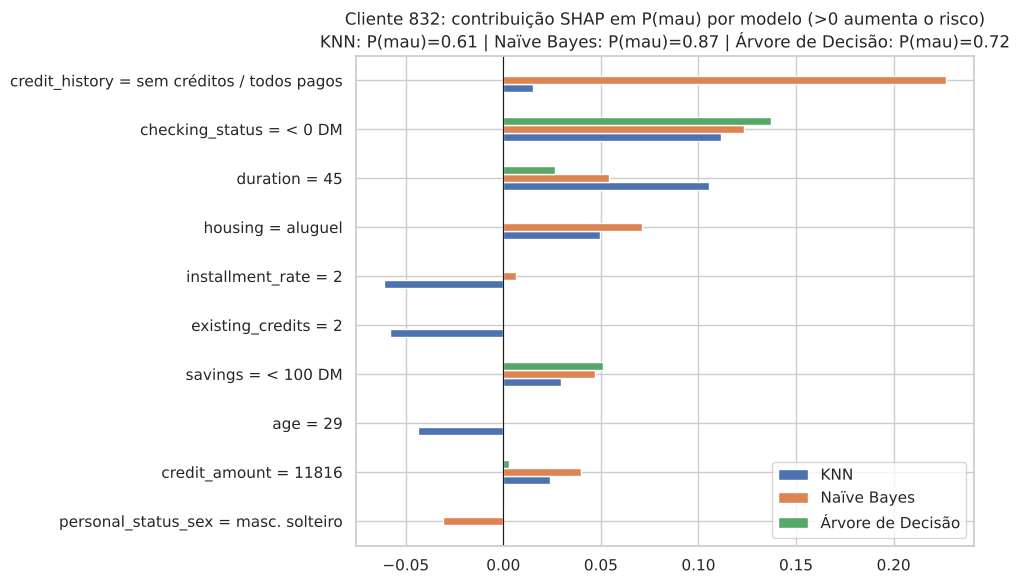

,KNN,Naïve Bayes,Árvore de Decisão
credit_history = sem créditos / todos pagos,0.015,0.227,0.000
checking_status = < 0 DM,0.111,0.123,0.137
duration = 45,0.105,0.054,0.027
housing = aluguel,0.049,0.071,0.000
installment_rate = 2,-0.061,0.006,0.000
existing_credits = 2,-0.058,0.000,0.000
savings = < 100 DM,0.030,0.047,0.051
age = 29,-0.044,0.000,0.000
credit_amount = 11816,0.024,0.040,0.003
personal_status_sex = masc. solteiro,0.000,-0.031,0.001


In [29]:
# mesma pessoa, três modelos: contribuições SHAP lado a lado
local = pd.DataFrame({n: sv.values[pos] for n, sv in shap_values.items()}, index=FEATURES)
local = local.loc[local.abs().max(axis=1).sort_values(ascending=False).index[:10]]
local.index = [f"{f} = {x_ex.iloc[0][f]}" for f in local.index]
fig, ax = plt.subplots(figsize=(10, 6))
local[::-1].plot.barh(ax=ax); ax.axvline(0, c="k", lw=.8)
ax.set_title(f"Cliente {ex_id}: contribuição SHAP em P(mau) por modelo (>0 aumenta o risco)\n"
             + " | ".join(f"{n}: P(mau)={models[n].predict_proba(x_ex)[0,1]:.2f}" for n in models))
plt.tight_layout(); plt.savefig(FIG / "shap_local_3modelos.png", dpi=130, bbox_inches="tight"); plt.show()
local.round(3)

**Mesmo cliente, três justificativas diferentes.** Os três modelos concordam que o cliente-exemplo é de
risco e que `checking_status = < 0 DM` pesa contra ele. Mas o **principal motivo** muda:
- **Naïve Bayes:** `credit_history = sem créditos / todos pagos` — justamente a regra contraintuitiva
  vista na EDA (quem pagou tudo seria *mais* arriscado);
- **Árvore:** saldo negativo + poupança baixa + prazo — só as 3 perguntas do seu caminho;
- **KNN:** prazo de 45 meses quase tanto quanto o saldo, e efeitos de `age`, `installment_rate` e
  `existing_credits` que os outros modelos ignoram.

Se o banco tivesse que explicar a recusa a este cliente, **a resposta dependeria do modelo escolhido** —
mesmo com todos chegando à mesma decisão.

# 4. Comparação e análise dos resultados (Etapa 4)

## 4.1 Os modelos concordam sobre as variáveis mais relevantes?
Consolidamos todas as medidas de importância em rankings e medimos a concordância com a
**correlação de Spearman** (correlação entre posições no ranking).

In [30]:
measures = pd.concat({
    "Árvore — impureza": imp_dt,
    "NB — |log-razão| média": imp_nb,
    **{f"{n} — permutação": perm[n] for n in models},
    **{f"{n} — SHAP": shap_imp[n] for n in models},
}, axis=1).reindex(FEATURES)

ranks = measures.rank(ascending=False, method="min").astype(int)
top5 = pd.DataFrame({c: measures[c].sort_values(ascending=False).index[:5].tolist() for c in measures},
                    index=[f"#{i}" for i in range(1, 6)])
display(top5.T)

,#1,#2,#3,#4,#5
Árvore — impureza,checking_status,duration,other_installment_plans,property,employment
NB — |log-razão| média,checking_status,savings,purpose,credit_history,duration
KNN — permutação,checking_status,personal_status_sex,duration,credit_amount,savings
Naïve Bayes — permutação,checking_status,credit_history,purpose,duration,age
Árvore de Decisão — permutação,checking_status,duration,savings,property,other_installment_plans
KNN — SHAP,checking_status,purpose,personal_status_sex,credit_history,duration
Naïve Bayes — SHAP,checking_status,savings,purpose,duration,credit_history
Árvore de Decisão — SHAP,checking_status,duration,savings,other_installment_plans,property


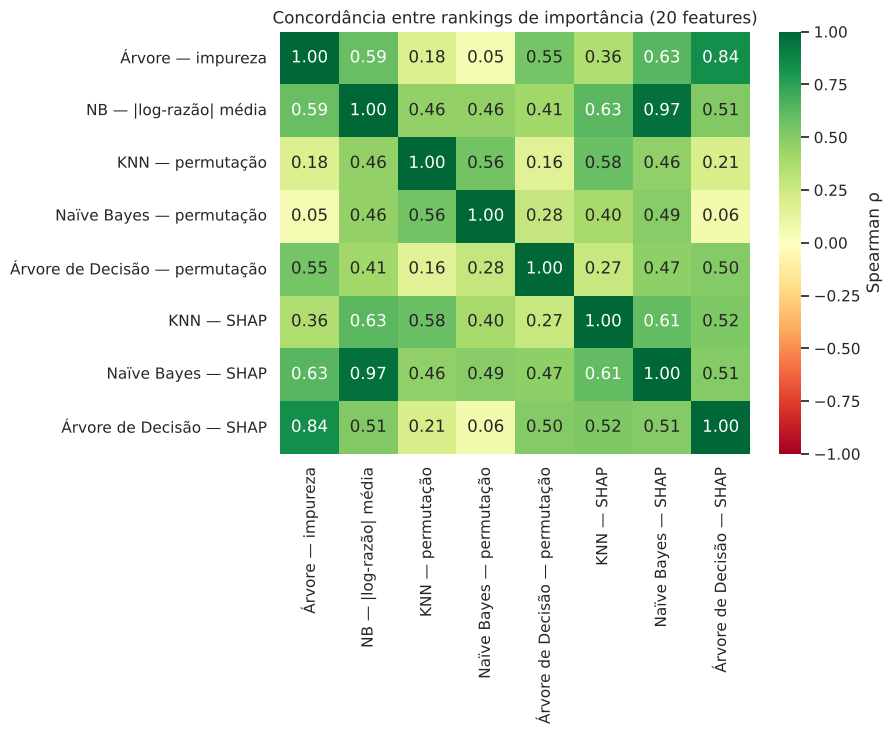

Spearman entre modelos (mesma ferramenta: SHAP):
                    KNN  Naïve Bayes  Árvore de Decisão
KNN                1.00         0.61               0.52
Naïve Bayes        0.61         1.00               0.51
Árvore de Decisão  0.52         0.51               1.00


In [31]:
rho = measures.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Concordância entre rankings de importância (20 features)")
plt.tight_layout(); plt.savefig(FIG / "concordancia_rankings.png", dpi=130, bbox_inches="tight"); plt.show()

shap_rho = shap_imp.corr(method="spearman")
print("Spearman entre modelos (mesma ferramenta: SHAP):")
print(shap_rho.round(2).to_string())

In [32]:
# Tabela-resumo: posição de cada feature no ranking SHAP de cada modelo
summary = ranks[[f"{n} — SHAP" for n in models]].copy()
summary.columns = list(models)
summary["posição média"] = summary.mean(axis=1)
summary.sort_values("posição média").head(10)

,KNN,Naïve Bayes,Árvore de Decisão,posição média
checking_status,1,1,1,1.000000
duration,5,4,2,3.666667
savings,7,2,3,4.000000
purpose,2,3,10,5.000000
property,6,6,5,5.666667
employment,8,7,6,7.000000
personal_status_sex,3,10,11,8.000000
credit_history,4,5,19,9.333333
credit_amount,10,11,7,9.333333
other_installment_plans,18,9,4,10.333333


In [33]:
# Atributos sensíveis: quanto cada modelo depende deles?
sens = ["age", "personal_status_sex", "foreign_worker"]
pd.concat({"rank SHAP": summary.loc[sens, list(models)],
           "SHAP médio |·|": shap_imp.loc[sens].round(4)}, axis=1)

rank SHAP                               SHAP médio |·|  \
                          KNN Naïve Bayes Árvore de Decisão            KNN   
age                        15          12                14         0.0146   
personal_status_sex         3          10                11         0.0285   
foreign_worker             20          16                20         0.0023   

                                                   
                    Naïve Bayes Árvore de Decisão  
age                      0.0156            0.0003  
personal_status_sex      0.0253            0.0004  
foreign_worker           0.0051            0.0000

## 4.2 Discussão

### Os resultados fazem sentido em relação ao problema?
**Em grande parte, sim.** Os três modelos, por mecanismos diferentes, chegam ao mesmo núcleo de variáveis
— **saldo em conta corrente, prazo, valor do crédito, histórico de crédito e poupança** — que são
exatamente os indicadores clássicos de capacidade e disposição de pagamento usados em análise de crédito.
A direção dos efeitos também é coerente: saldo negativo, prazos longos, valores altos e pouca poupança
aumentam o risco.

**Mas nem tudo.**
- O NB (e o KNN) aprenderam que `credit_history = conta crítica` *reduz* o risco (log-razão −0,70), e que
  “sem créditos / todos pagos” o *aumenta* (+1,27). É estatisticamente verdadeiro nesta amostra, mas
  contraria o bom senso de crédito e provavelmente reflete **viés de seleção** (o banco só aprovou os
  “críticos” mais seguros) e/ou **erro de codificação** do dataset (Grömping, 2019). Em produção, um
  cliente com histórico crítico seria *favorecido* — problema que **nenhuma métrica revelaria**.
- O KNN usa **sexo/estado civil** como 3ª variável mais importante — sem justificativa de negócio e com
  risco de discriminação.

### Os três modelos concordam sobre as variáveis mais relevantes?
- **No topo, sim**: `checking_status` é a variável nº 1 em **todas** as 8 medidas, nos três modelos.
  `duration` e `savings` também estão no top-5 da maioria.
- **No resto, só parcialmente**: a correlação de Spearman entre os rankings SHAP é moderada
  (KNN×NB ≈ 0,61; KNN×Árvore ≈ 0,52; NB×Árvore ≈ 0,51). Exemplos de desacordo:
  - `purpose` é 2ª no KNN e 3ª no NB, mas 10ª na árvore (que não a usa);
  - `credit_history` é 4ª–5ª no KNN e NB, e não é usada pela árvore;
  - `personal_status_sex` é 3ª no KNN e ≥ 10ª nos outros.
- A árvore é **esparsa** (usa 7 de 20 features); NB e KNN usam um pouco de todas. Os valores SHAP
  pequenos (≈ 0,0003) atribuídos a features que a árvore *não usa* são ruído de amostragem do
  `KernelExplainer` — um lembrete de que o SHAP também é uma estimativa.
- Modelos com **desempenho semelhante** usam a informação de forma **diferente**: o NB soma evidências
  independentes; a árvore cria regras com interações (“prazo longo *e* sem poupança”); o KNN usa
  semelhança global. É o chamado **efeito Rashomon**: muitos modelos igualmente bons, com explicações
  diferentes.
- As duas ferramentas agnósticas também diferem entre si: a **permutação** mede impacto no *desempenho*
  (pode dar valores ≈ 0 ou negativos para features que o modelo usa mas não ajudam a acertar), o **SHAP**
  mede impacto na *previsão*.

### Quais ferramentas foram usadas em cada modelo?

| | Árvore de Decisão | Naïve Bayes | KNN |
|---|---|---|---|
| **Intrínseca (global)** | estrutura da árvore, regras (`export_text`), importância por impureza | tabelas P(valor\|classe), log-razão de verossimilhança | — (não há) |
| **Intrínseca (local)** | caminho de decisão | decomposição aditiva exata do log-odds | vizinhos mais próximos (por exemplos) |
| **Agnóstica** | permutação, SHAP | permutação, SHAP | permutação, SHAP (global e local), LIME |

### O que essas ferramentas permitiram compreender?
- **Árvore:** a lógica completa de decisão em ~5 perguntas; que atributos sensíveis não são usados; que
  alguns ramos não alteram a classe final.
- **Naïve Bayes:** o *quanto* cada valor de cada atributo pesa (ex.: saldo < 0 DM multiplica a chance de
  “mau” por ≈ 2,1); a decomposição exata de qualquer previsão; e a regra contraintuitiva de `credit_history`.
- **KNN:** que seu comportamento é dominado por `checking_status` (confiança), mas também por
  sexo/estado civil (alerta); que explicações por exemplos (vizinhos) não bastam para justificar uma
  decisão; e que SHAP e LIME podem discordar nos detalhes.
- **Agnósticas:** uma régua comum para comparar os três modelos e checar o uso de atributos sensíveis.

### Principais limitações de cada modelo quanto à interpretabilidade

| Modelo | Limitações |
|---|---|
| **Árvore** | Só é legível se rasa (menor AUC: 0,70 vs 0,78 do NB). Regras grosseiras: todos os clientes de uma folha recebem a mesma resposta. Instável: outra amostra gera outra árvore. Importância por impureza enviesada para variáveis contínuas e calculada no treino. Fronteiras em degrau (crédito de 3.449 vs 3.451 DM muda a classe). |
| **Naïve Bayes** | Independência falsa → evidência correlacionada contada em dobro e probabilidades extremas (mal calibradas). Não representa interações. A discretização (faixas) é uma escolha arbitrária que muda a explicação. |
| **KNN** | Sem explicação nativa por feature; o que importa depende do pré-processamento e da métrica de distância (daí o peso indevido de sexo/estado civil). Precisa de SHAP/LIME, que são aproximações *post-hoc*: o LIME teve baixa fidelidade local (R² ≈ 0,19) e diverge do SHAP nos fatores secundários; o SHAP Kernel é caro e assume independência entre features ao perturbar. Exige guardar a base de treino (explicar via vizinhos expõe dados de outros clientes). |

# 5. Desafio final e conclusões

> **Como a interpretabilidade pode contribuir para que as previsões de modelos de AM sejam
> compreendidas e utilizadas de maneira mais consciente?**

Com base nos experimentos:

1. **Métricas não bastam.** O NB teve o melhor AUC; a árvore, o melhor recall e custo; o KNN ficou no
   meio. Nenhum desses números diz *se o modelo está certo pelos motivos certos*. Foi a interpretabilidade
   que mostrou que os três se apoiam em `checking_status`, prazo e poupança (o que gera confiança) **e**
   que o NB e o KNN aprenderam uma regra provavelmente espúria sobre `credit_history` (o que exige
   revisão dos dados).

2. **Auditoria de vieses.** O KNN — com desempenho razoável — tem **sexo/estado civil como 3ª variável
   mais influente**, por um efeito colateral do one-hot + distância. A árvore não usa o atributo; o NB, pouco.
   Sem SHAP e permutação, esse modelo poderia ir para produção discriminando clientes. Esse tipo de
   verificação é pré-requisito para usar modelos em crédito de forma ética e legal.

3. **Explicações para quem é afetado.** O caminho da árvore, a decomposição do NB e o waterfall do SHAP
   permitem dizer ao cliente recusado *quais fatores* pesaram (ex.: “saldo negativo em conta e ausência de
   poupança”) — o que atende ao direito de revisão de decisões automatizadas (LGPD art. 20) e permite ao
   cliente agir.

4. **Escolha consciente do modelo.** Há um *trade-off* real: a árvore rasa é a mais transparente, mas a
   de menor AUC e com regras grosseiras; o NB é ao mesmo tempo o de melhor AUC e exatamente decomponível;
   o KNN depende de explicações aproximadas e revelou uso de atributo sensível. Para este problema, o
   **Naïve Bayes** oferece o melhor equilíbrio desempenho × interpretabilidade (após revisar
   `credit_history`); a **árvore** é a melhor ferramenta para *comunicar* regras a gestores; o **KNN**,
   como está, **não** deveria ser usado.

5. **As explicações também têm limites.** SHAP e LIME descrevem o modelo, não a realidade causal; podem
   divergir entre si e entre execuções. Usá-las de forma consciente significa triangular várias técnicas
   (como fizemos) e confrontá-las com o conhecimento do domínio.

**Conclusão:** avaliar um modelo é responder a duas perguntas — *ele acerta?* e *por que ele acerta?*.
Neste trabalho, a segunda pergunta revelou problemas nos dados, um viés no KNN, confirmou o uso de
variáveis legítimas e mostrou que modelos com desempenho parecido raciocinam de maneiras diferentes. É essa compreensão que
permite usar a previsão como **apoio** a uma decisão humana informada, e não como uma resposta opaca.

### Referências
- Hofmann, H. (1994). *Statlog (German Credit Data)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77
- Grömping, U. (2019). *South German Credit Data: Correcting a Widely Used Data Set*. Report 4/2019, Beuth University of Applied Sciences Berlin.
- Lundberg, S. & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS.
- Ribeiro, M. T., Singh, S. & Guestrin, C. (2016). *“Why Should I Trust You?”: Explaining the Predictions of Any Classifier*. KDD.
- Molnar, C. (2022). *Interpretable Machine Learning*. https://christophm.github.io/interpretable-ml-book/